In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:40397")
client

<Client: 'tcp://127.0.0.1:40397' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op

from scipy.interpolate import griddata

import xrft
import gsw

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
la = np.arange(10,60,10)
dlo = 11.5
lo = np.arange(-96.,-15,11.5)

In [5]:
# for pp in range(7,9):
#     if pp == 7:
#         ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
#                             ).chunk({"time":10,"y":400,"x":400})
#     else:
#         tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
#                             ).chunk({"time":10,"y":400,"x":400}
#                                    ).isel(time=slice(1,None))
#         time = tmp.time.data + ds.time[-1].data
#         tmp = tmp.reset_index("time", drop=False)
#         tmp = tmp.reset_coords("time", drop=True)
#         tmp.coords["time"] = ("time", time)
#         ds = xr.concat([ds, tmp], "time")
#         tmp.close()
dsb = xr.open_zarr(op.join(ddir,"SW/mean/UVh.zarr"))
dsp  = xr.open_zarr(op.join(ddir,"SW/TWA/Up.zarr"))
dspp = xr.open_zarr(op.join(ddir,"SW/TWA/Upp.zarr"))
# dpv = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi.zarr"))
dpvb2z = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/b-to-Z.zarr"))
# dpvz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ.zarr"))
dpvz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ_grad1st.zarr"))


dsb, dsp, dspp, dpvz

(<xarray.Dataset> Size: 671MB
 Dimensions:  (level: 4, y: 2048, x: 4096)
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
 Data variables:
     hbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     ubar     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     uhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     vbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     vhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>,
 <xarray.Dataset> Size: 141GB
 Dimensions:  (time: 419, level: 5, y: 2048, x: 4096)
 Coordinates:
   * time     (time) float32 2kB 0.0 2.592e+06 5.184e+06 ... 1.081e+09 1.083e+09
   * level    (level) float32 20B

In [8]:
for ireg in range(1,28):
    if op.exists(op.join(ddir,"SW/TWA/%02d" % ireg)):
        dsu = xr.open_zarr(op.join(ddir,"SW/TWA/%02d/U-interp.zarr" 
                                   % ireg))
    
        Fup = xrft.isotropic_power_spectrum(dsu.up.fillna(0.), dim=["y","x"],
                                            detrend="linear", window="hann",
                                            window_correction=True
                                           ).mean("time")
        Fvp = xrft.isotropic_power_spectrum(dsu.vp.fillna(0.), dim=["y","x"],
                                            detrend="linear", window="hann",
                                            window_correction=True
                                           ).mean("time")
        Fupp = xrft.isotropic_power_spectrum(dsu.upp.fillna(0.), dim=["y","x"],
                                            detrend="linear", window="hann",
                                            window_correction=True
                                           ).mean("time")
        Fvpp = xrft.isotropic_power_spectrum(dsu.vpp.fillna(0.), dim=["y","x"],
                                            detrend="linear", window="hann",
                                            window_correction=True
                                           ).mean("time")
    
        Ep = .5*(Fup+Fvp)
        Epp = .5*(Fupp+Fvpp)
        dsave = Ep.to_dataset(name="Ep")
        dsave["Epp"] = Epp
        print(dsave)
        dsave.to_zarr(op.join(ddir,"SW/TWA/%02d/Eh.zarr" % ireg), 
                      mode="w")

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables 

<xarray.Dataset> Size: 3kB
Dimensions:  (freq_r: 121)
Coordinates:
  * freq_r   (freq_r) float64 968B 1.689e-06 4.039e-06 ... 0.0003155 0.0003179
Data variables:
    Ep       (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>
    Epp      (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/e

<xarray.Dataset> Size: 3kB
Dimensions:  (freq_r: 121)
Coordinates:
  * freq_r   (freq_r) float64 968B 1.689e-06 4.039e-06 ... 0.0003155 0.0003179
Data variables:
    Ep       (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>
    Epp      (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/e

<xarray.Dataset> Size: 3kB
Dimensions:  (freq_r: 121)
Coordinates:
  * freq_r   (freq_r) float64 968B 1.689e-06 4.039e-06 ... 0.0003155 0.0003179
Data variables:
    Ep       (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>
    Epp      (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>


... (30 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/e

<xarray.Dataset> Size: 3kB
Dimensions:  (freq_r: 121)
Coordinates:
  * freq_r   (freq_r) float64 968B 2.167e-06 5.253e-06 ... 0.0003995 0.0004027
Data variables:
    Ep       (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>
    Epp      (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/e

<xarray.Dataset> Size: 3kB
Dimensions:  (freq_r: 121)
Coordinates:
  * freq_r   (freq_r) float64 968B 2.167e-06 5.253e-06 ... 0.0003995 0.0004027
Data variables:
    Ep       (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>
    Epp      (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>


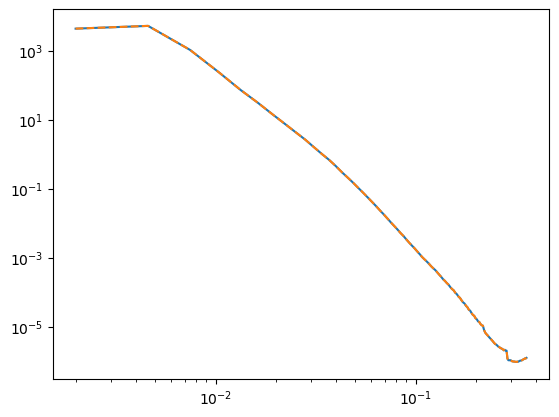

In [11]:
ireg = 17
dse = xr.open_zarr(op.join(ddir,"SW/TWA/%02d/Eh.zarr" % ireg))

fig, ax = plt.subplots()
ax.plot(dse.freq_r*1e3, dse.Ep)
ax.plot(dse.freq_r*1e3, dse.Epp, ls="--")
ax.set_xscale("log")
ax.set_yscale("log")

In [ ]:
for ireg in range(1,28):
    if op.exists(op.join(ddir,"SW/TWA/%02d" % ireg)):
        dsP = xr.open_zarr(op.join(ddir,"SW/TWA/%02d/PVinZ-interp.zarr" 
                                   % ireg))
    
        Zp = xrft.isotropic_power_spectrum(dsP.Pip.fillna(0.), dim=["y","x"],
                                            detrend="linear", window="hann",
                                            window_correction=True
                                           ).mean("time")
        Zd = xrft.isotropic_power_spectrum(dsP.Pidagger.fillna(0.), dim=["y","x"],
                                            detrend="linear", window="hann",
                                            window_correction=True
                                           ).mean("time")
        # Zf = xrft.isotropic_power_spectrum(dsP.Piflat.fillna(0.), dim=["y","x"],
        #                                     detrend="linear", window="hann",
        #                                     window_correction=True
        #                                    ).mean("time")
    
        dsave = Zp.to_dataset(name="Zp")
        dsave["Zdagger"] = Zd
        # dsave["Zflat"] = Zf
        print(dsave)
        dsave.to_zarr(op.join(ddir,"SW/TWA/%02d/ZinZ.zarr" % ireg), 
                      mode="w")

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)


<xarray.Dataset> Size: 3kB
Dimensions:  (freq_r: 121)
Coordinates:
  * freq_r   (freq_r) float64 968B 1.689e-06 4.039e-06 ... 0.0003155 0.0003179
Data variables:
    Zp       (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>
    Zdagger  (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:991: FutureWarning: Isotropic wavenumber larger than the Nyquist wavenumber may result.
  warnings.warn(msg, FutureWarning)
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/xrft/xrft.py:456: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  daft = daft.drop([d for d in dim if d in daft.coords])
/storage/tartar/takaya/miniconda3/e

<xarray.Dataset> Size: 3kB
Dimensions:  (freq_r: 121)
Coordinates:
  * freq_r   (freq_r) float64 968B 1.689e-06 4.039e-06 ... 0.0003155 0.0003179
Data variables:
    Zp       (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>
    Zdagger  (freq_r) float64 968B dask.array<chunksize=(121,), meta=np.ndarray>


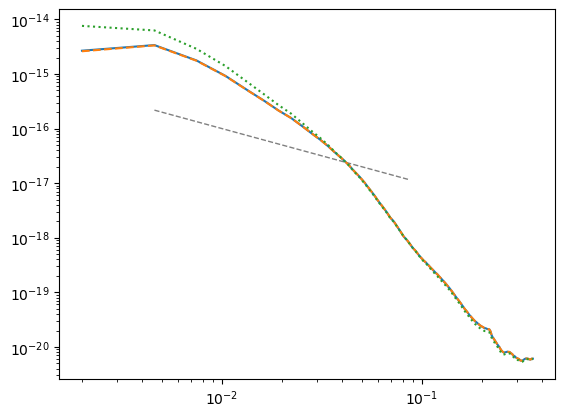

In [12]:
ireg = 16
dsz = xr.open_zarr(op.join(ddir,"SW/TWA/%02d/Z.zarr" % ireg))
dszz = xr.open_zarr(op.join(ddir,"SW/TWA/%02d/ZinZ.zarr" % ireg))

fig, ax = plt.subplots()
ax.plot(dsz.freq_r[1:30]*1e3, dsz.freq_r[1:30]**-1*1e-21, 
        ls="--", c="grey", lw=1)

ax.plot(dsz.freq_r*1e3, dszz.Zdagger)
ax.plot(dsz.freq_r*1e3, dsz.Zflat, ls="--")
ax.plot(dsz.freq_r*1e3, dszz.Zp, ls=":")
ax.set_xscale("log")
ax.set_yscale("log")

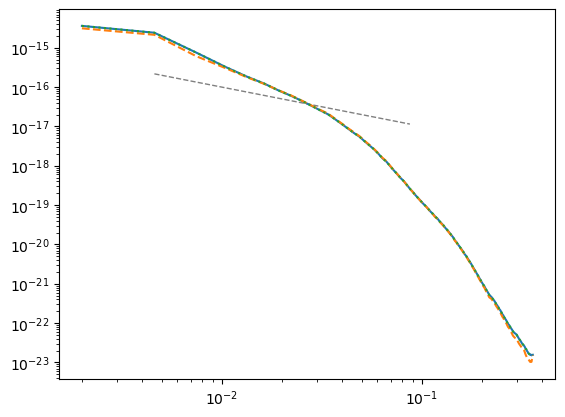

In [6]:
ireg = 18
dsz = xr.open_zarr(op.join(ddir,"SW/TWA/%02d/Z.zarr" % ireg))
dszz = xr.open_zarr(op.join(ddir,"SW/TWA/%02d/ZinZ.zarr" % ireg))

fig, ax = plt.subplots()
ax.plot(dsz.freq_r[1:30]*1e3, dsz.freq_r[1:30]**-1*1e-21, 
        ls="--", c="grey", lw=1)

ax.plot(dsz.freq_r*1e3, dszz.Zdagger)
ax.plot(dsz.freq_r*1e3, dsz.Zflat, ls="--")
ax.plot(dsz.freq_r*1e3, dszz.Zp, ls=":")
ax.set_xscale("log")
ax.set_yscale("log")